<a href="https://colab.research.google.com/github/antoine-jossien/2026_Intro_Python/blob/main/live/part-I/FEEDBACK_JOSSIEN_ANTOINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

## Exercise 1: Hurricane track analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/nasa-hurricane-florence-2018-09-11.jpg" alt="A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud" width="500">

<em>Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from <a href="https://worldview.earthdata.nasa.gov/">NASA Worldview</a> via <a href="https://commons.wikimedia.org/wiki/File:Florence_2018-09-11_1750Z.jpg">Wikimedia Commons</a>, public domain.</em>


*Can you quickly find out which US states Hurricane Florence passed through using geopandas?*

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence
from 30 August to 18 September 2018. The track is the archived advisory record from the
[National Hurricane Center](https://www.nhc.noaa.gov/); the state boundaries are a
[US Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html)
cartographic boundary file.

References:

1. [Introduction to GeoPandas](https://geopandas.org/en/stable/getting_started/introduction.html) — geopandas' official website
2. [Geopandas: an introduction](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-2/geopandas-an-introduction.html) — Automating GIS Processes
3. [Use Data for Earth and Environmental Science in Open Source Python](https://www.earthdatascience.org/courses/use-data-open-source-python/)
4. [The Shapely User Manual](https://shapely.readthedocs.io/en/stable/manual.html)
5. [Geospatial Analysis with Python and R](https://kodu.ut.ee/~kmoch/geopython2020/index.html)

In [4]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Where the tools come from**

Every tool the questions need has been demonstrated already. `read_file`, `.plot()`, `GeoDataFrame`,
`gpd.points_from_xy`, `.crs`, `geom_type`, the MultiPolygon type, `.isin()`, `overlay`, `.centroid`,
`to_crs`, `buffer` and the spatial predicates are from this subchapter's lecture; `.head()` and
boolean filtering are from 1.5, and `unique` from 1.5's earthquake exercise. `ax.annotate`, which Q8
uses to label each state, is from 1.4.

**Q1) Import geopandas and pandas.**

Import geopandas as `gpd`, pandas as `pd`, and matplotlib's pyplot as `plt`.

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

**Q2) Read the state boundary file with geopandas' `read_file` function.**

The file is cached at `states_path`. Call the result `country`.

In [6]:
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [7]:
country.head(5)
country.geom_type

# it contains multipolygon and polygon

,0
0,MultiPolygon
1,MultiPolygon
2,Polygon
3,Polygon
4,MultiPolygon
5,Polygon
6,Polygon
7,MultiPolygon
8,Polygon
9,MultiPolygon


**Q4) Have a look at the data on a map using geopandas' `.plot()` method.**

Exclude Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method. Specify the
figsize to be 30 x 20.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

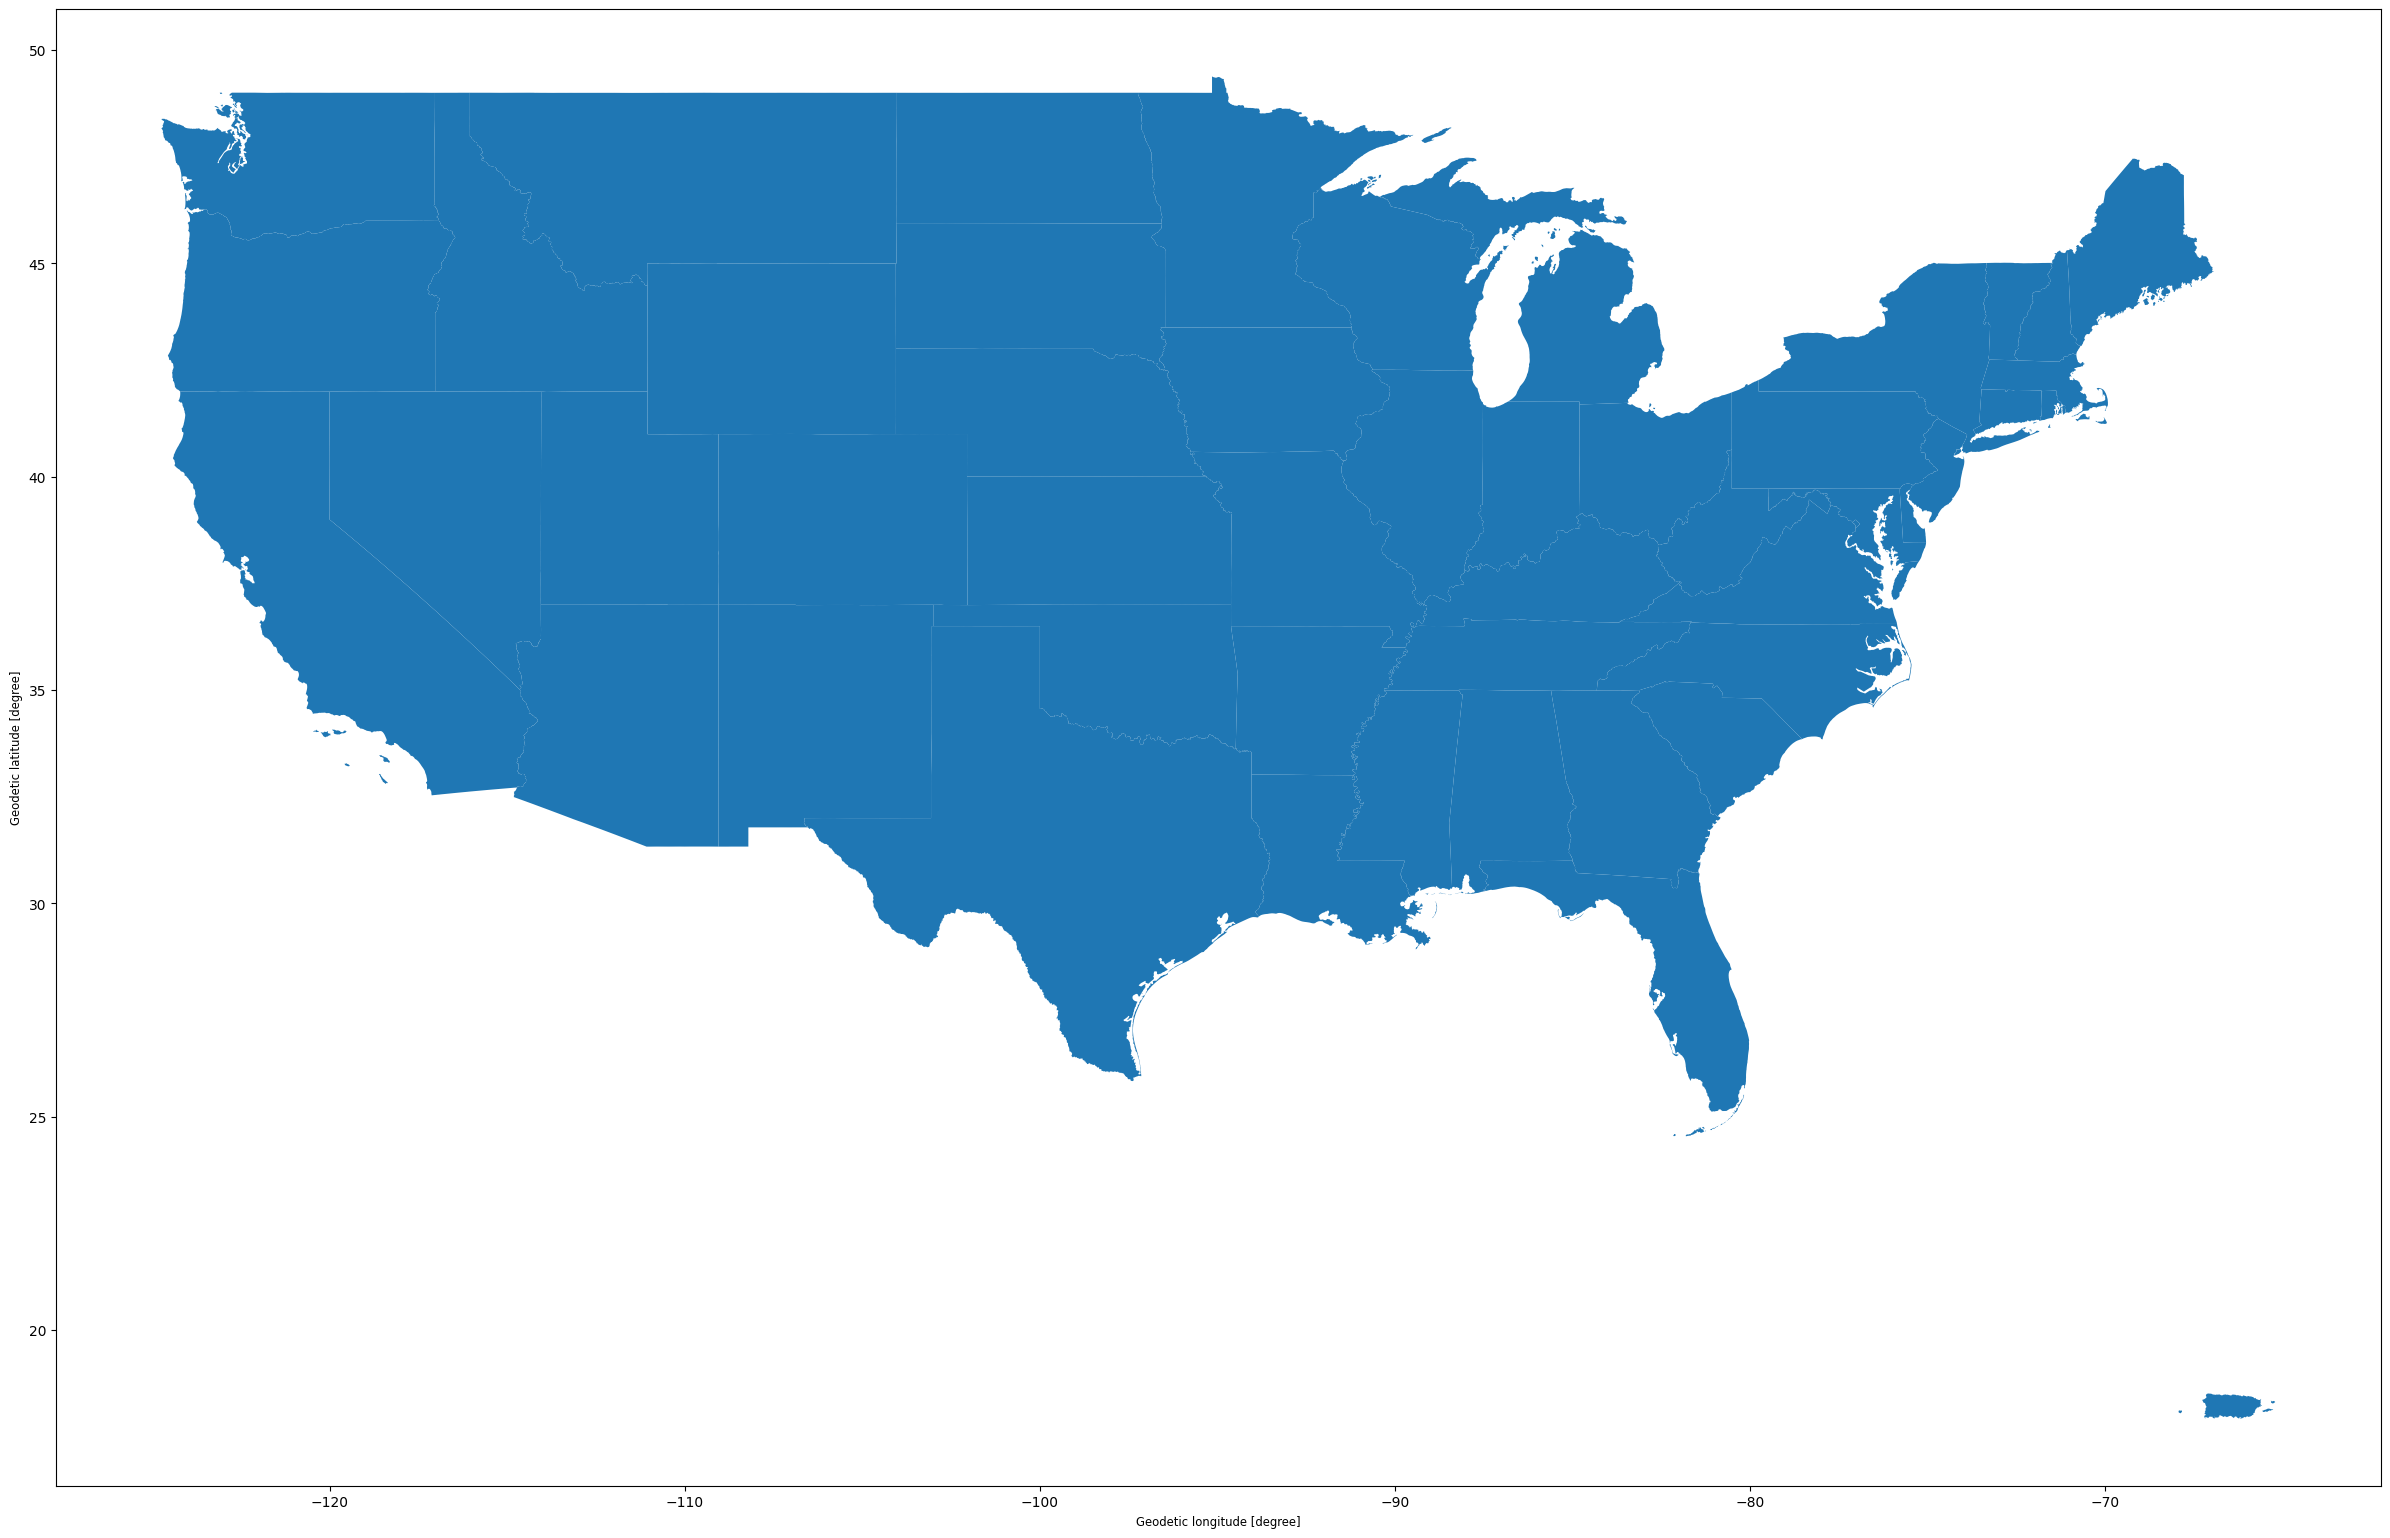

In [8]:
map = country[~country["NAME"].isin(["Alaska", "Hawaii"])]
map.plot(figsize=(30,20))

In [9]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.
florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


**Q5) Create a GeoDataFrame from the `florence` DataFrame.**

Build the geometry column from the `Long` and `Lat` columns with
[`gpd.points_from_xy`](https://geopandas.org/en/stable/docs/reference/api/geopandas.points_from_xy.html),
and call the result `gdf_florence`. Then look at its first few rows.

In [10]:
gdf_florence = gpd.GeoDataFrame(florence, geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]), crs="EPSG:4326") # set the crs as the same as map
gdf_florence.head(5)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-18.4 12.9)
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19 12.9)
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19.4 12.9)
3,08/30/2018 20:00,13.1,-20.4,30,1007,W at 11 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.4 13.1)
4,08/30/2018 23:00,13.2,-20.9,35,1007,W at 13 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.9 13.2)


**Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands out.

<function matplotlib.pyplot.show(close=None, block=None)>

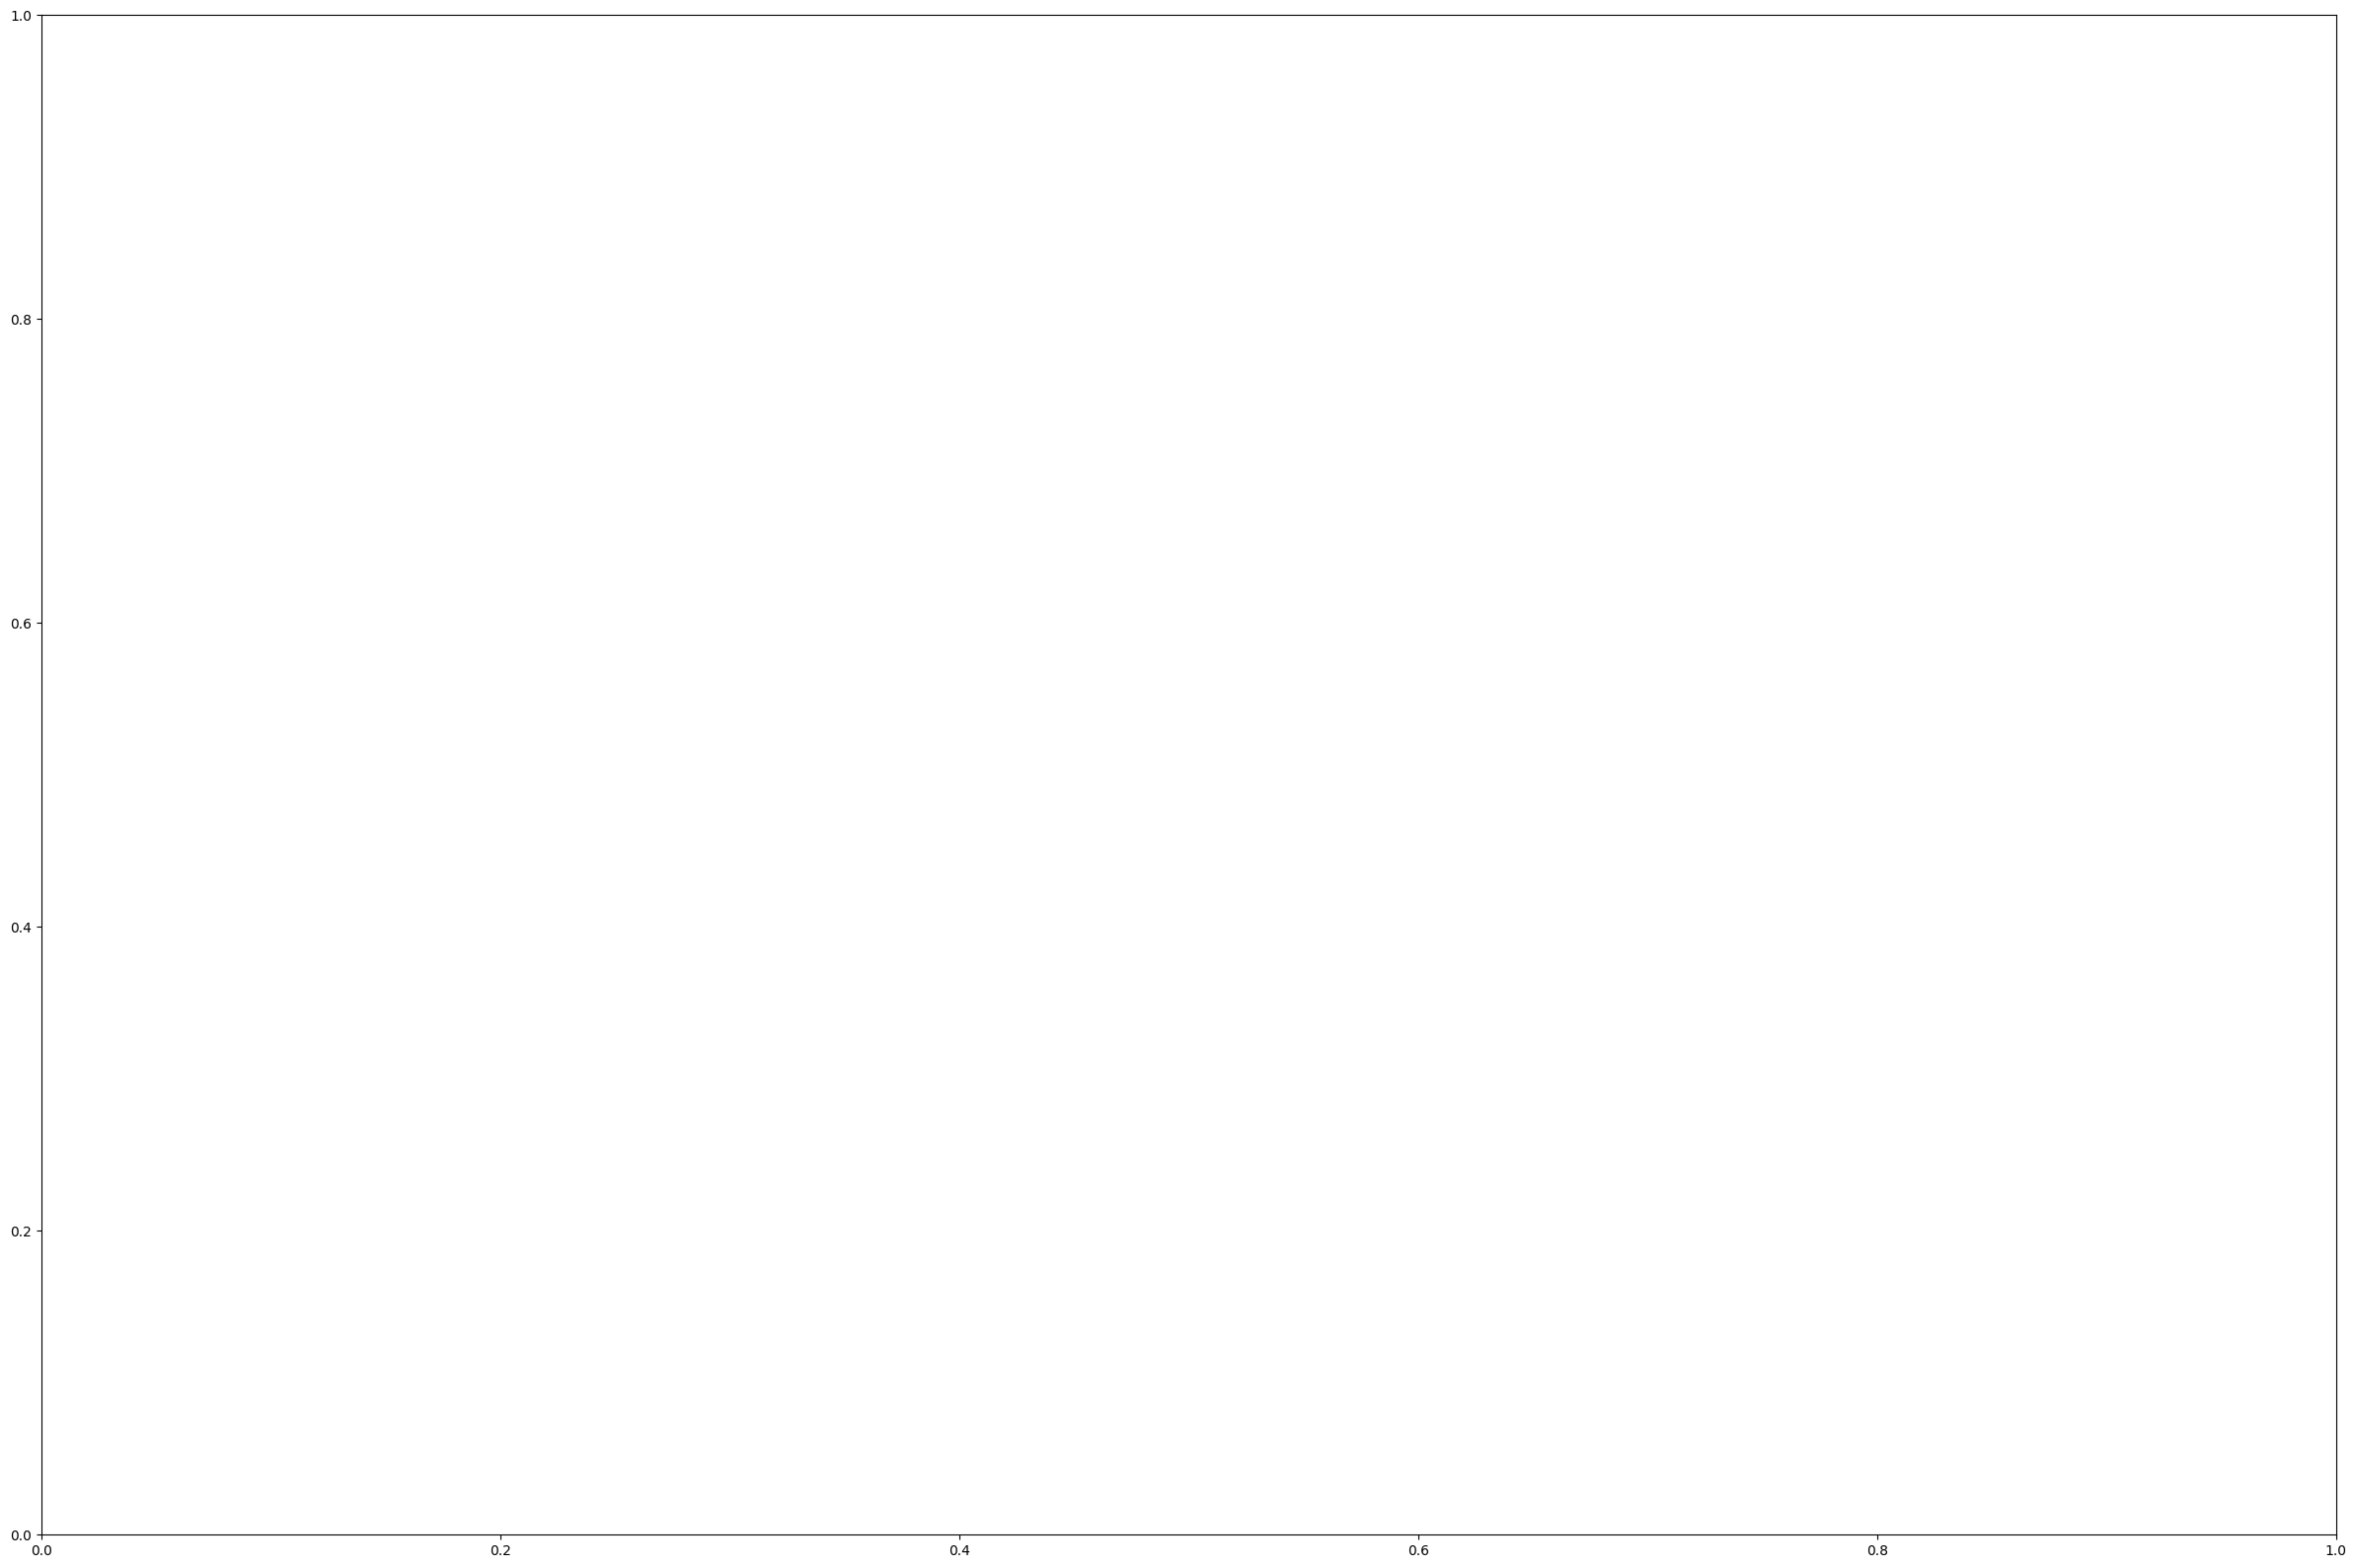

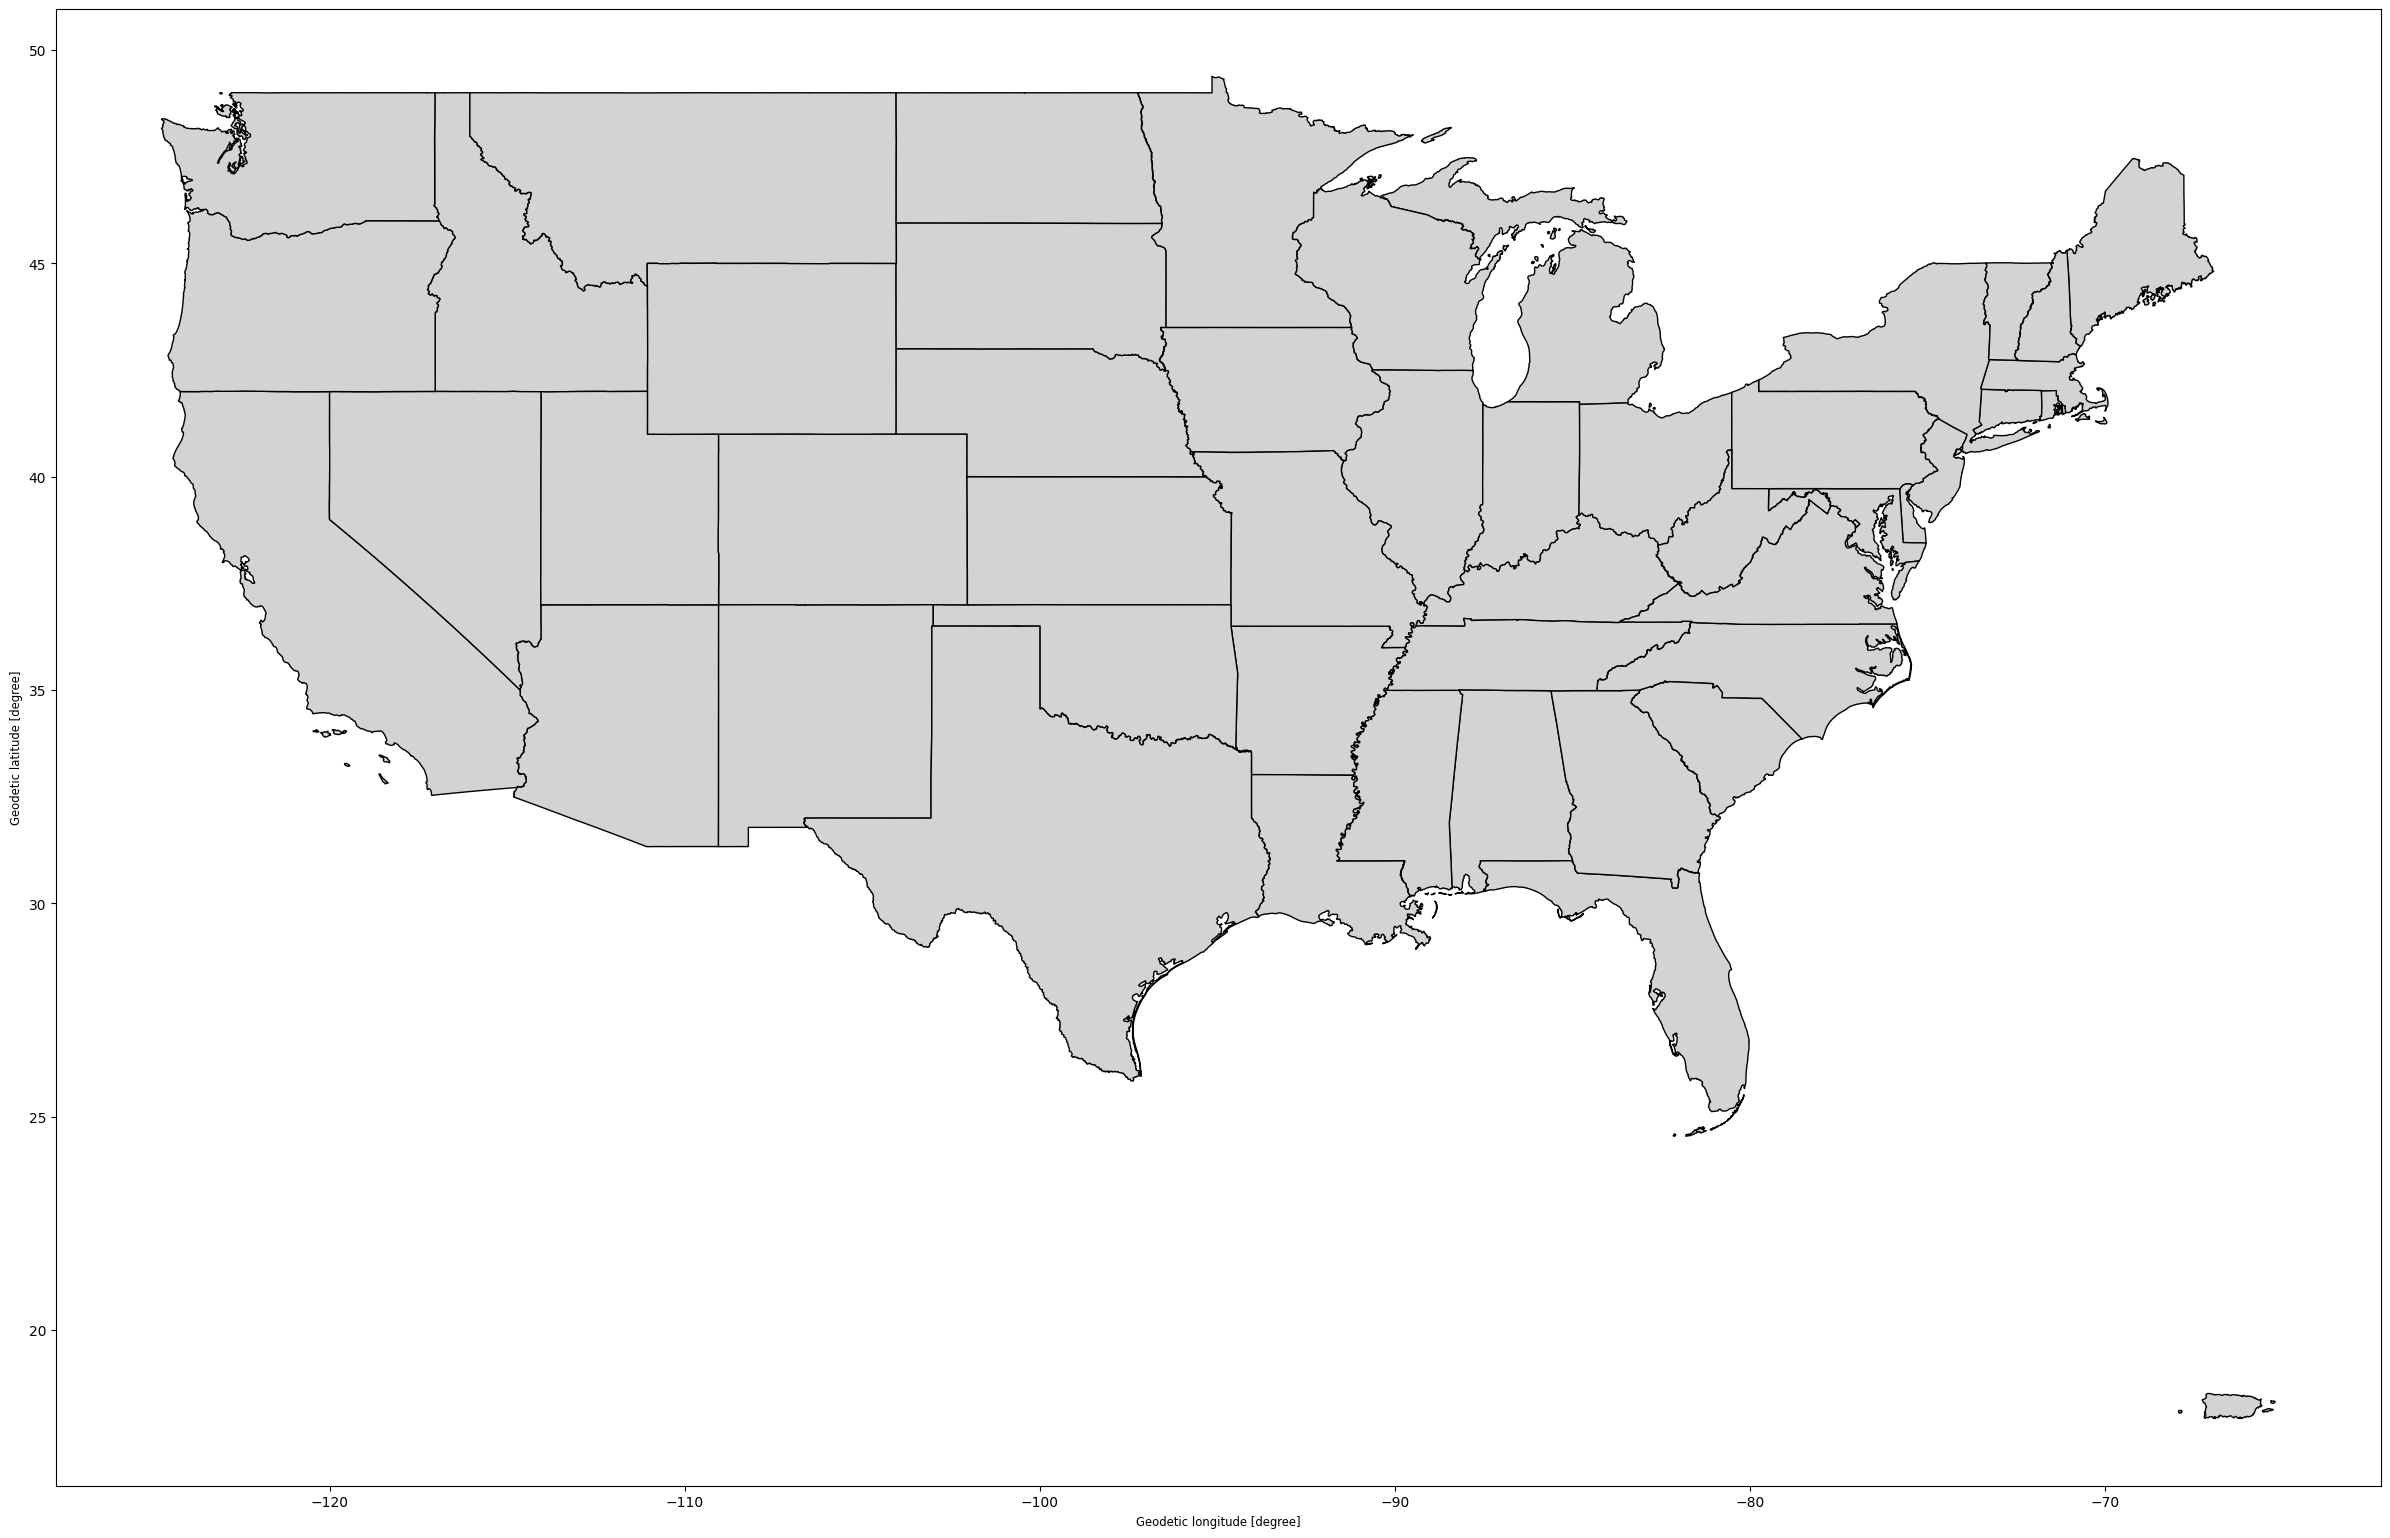

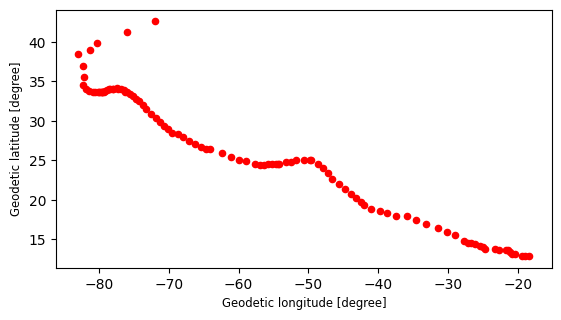

In [11]:
fig = plt.subplots(figsize=(30,20))
map.plot(figsize=(30,20), facecolor="lightgrey", edgecolor="k")
gdf_florence.plot(color="red", markersize = 20)
plt.show

**Markdown paragraph describing a
compelling challenge:**

i)
```python
fig = plt.subplots(figsize=(30,20))
map.plot(figsize=(30,20), facecolor="lightgrey", edgecolor="k")
gdf_florence.plot(color="red", markersize = 20)
plt.show
```
When plotting, two figures don't share the same axes

ii) we have to put fig, ax = suplots(figsize=(30,20))
and ax = ax into map.plot and gdf_florence.plot then they will share the same axe and be superposed

<function matplotlib.pyplot.show(close=None, block=None)>

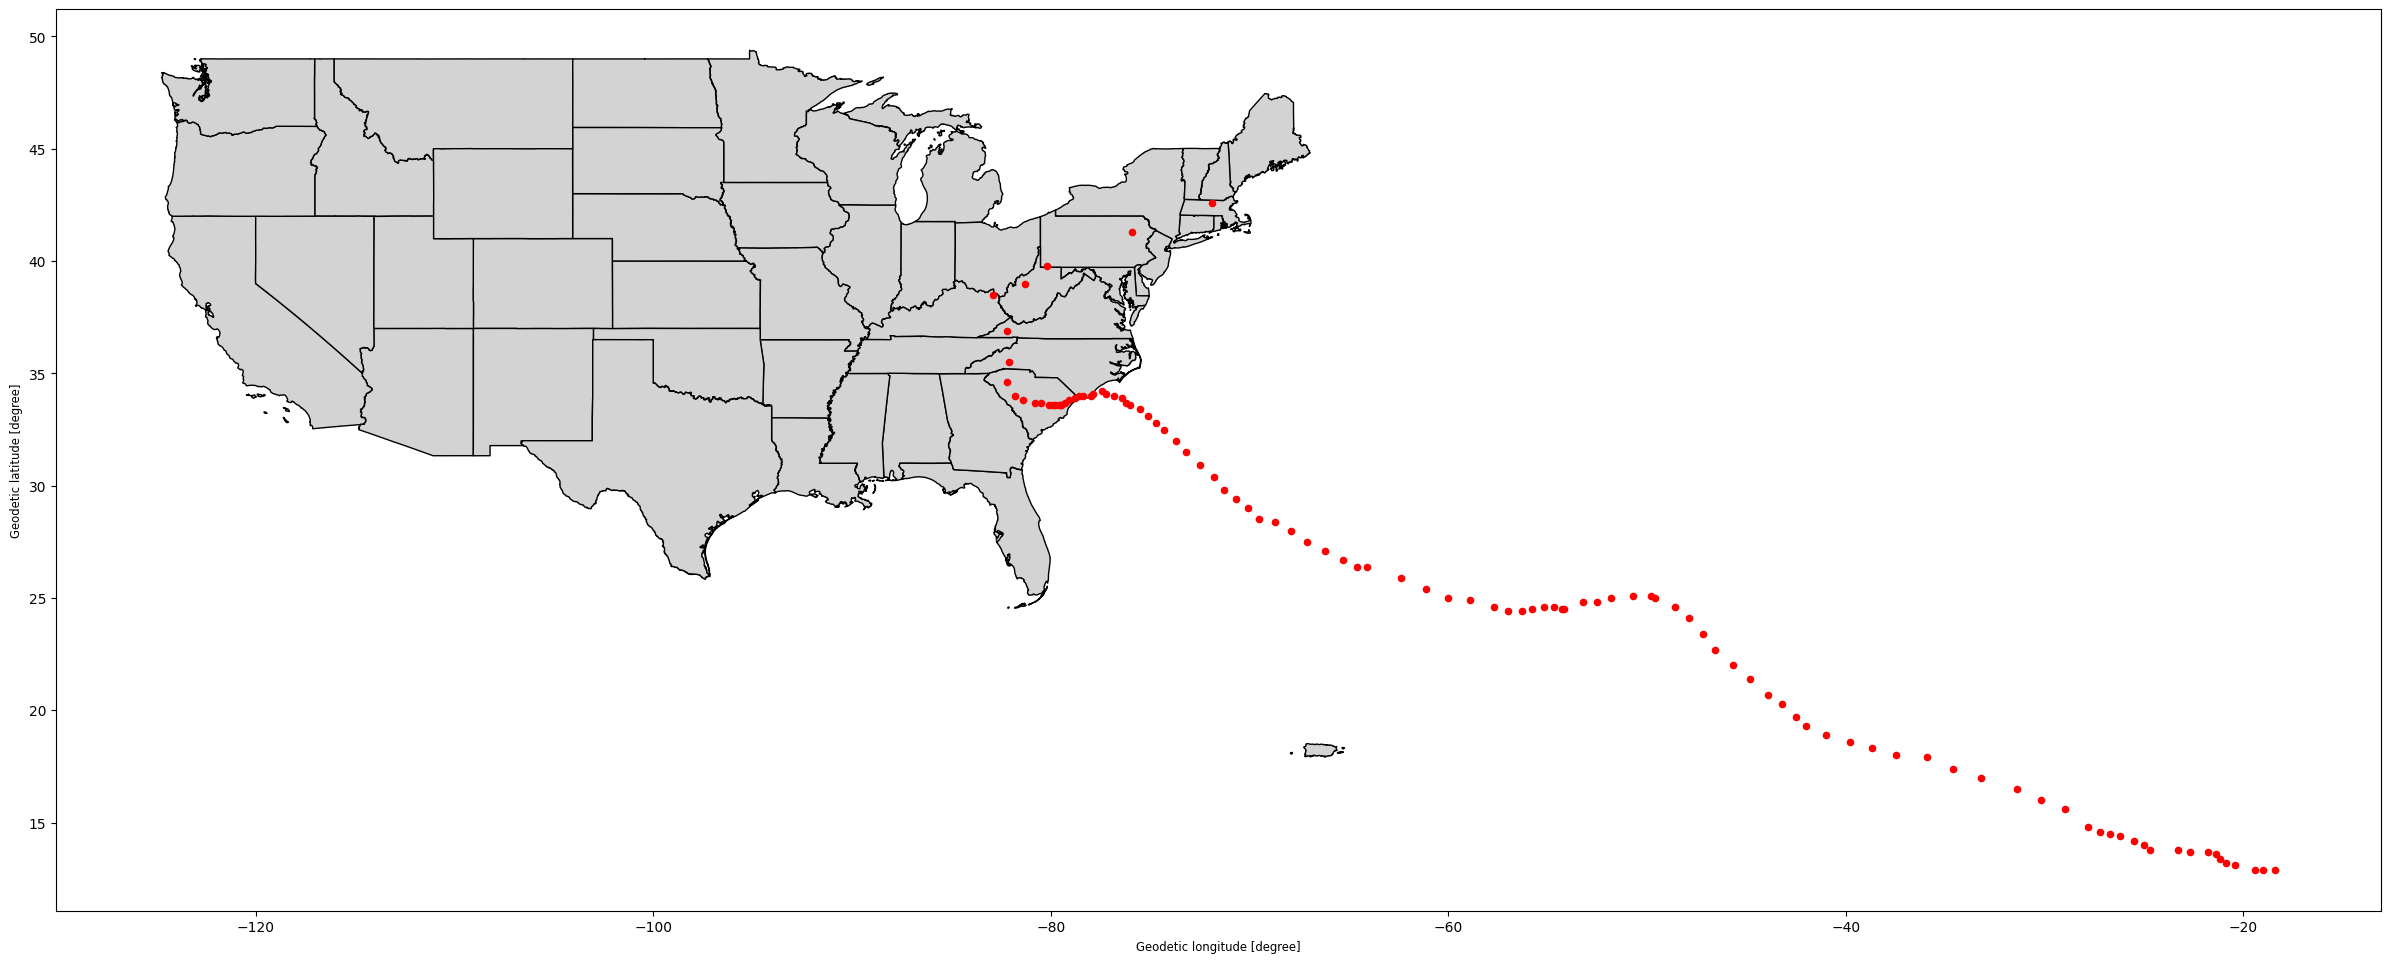

In [12]:
# correction
fig, ax = plt.subplots(figsize=(30,20))
map.plot(ax = ax, figsize=(30,20), facecolor="lightgrey", edgecolor="k")
gdf_florence.plot(ax = ax, color="red", markersize = 20)
plt.show

Q7) What is the coordinate reference system of the data?

Check it for both layers, and say in a comment whether they match — two layers only line up on one pair of axes if they share a crs.

In [13]:
print("states:", country.crs)
print("florence:", gdf_florence.crs)
print(country.crs == gdf_florence.crs) # True because I set it in the geodataframe

states: EPSG:4326
florence: EPSG:4326
True


Q8) Which states did the hurricane pass through?

ℹ️ Hint

One approach is to plot the trajectory over the US map, annotate each state with its name, and read the answer off the figure. Other approaches are more than welcome — overlay with how="intersection" will give you the track points that fall inside a state polygon, and the NAME column of the result then answers the question directly.

In [14]:
states_inside = []

for state_name in country["NAME"]:
  state_geom = map[country["NAME"] == state_name] # takes every states names in column NAME
  if gdf_florence.intersects(state_geom): # takes only states that intersect with gdf_florence
    states_inside.append(state_name) # add the intersects states to states_inside vector
print("states inside hurricane:", state_name)

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:1933: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
/tmp/ipykernel_4705/2189368358.py:5: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  if gdf_florence.intersects(state_geom):


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

i) I try to use a loop because it was simplest for me but it returns an error:
I don't need to use a if - loop :
if gdf_florence.intersects(state_geom):
    states_inside.append(state_name)
print("states inside hurricane:", state_name)

ii) I just had to use gdp.overlay:
inside = gpd.overlay(gdf_florence, map, how="intersection")
states_passed = inside["NAME].unique().tolist()
print(states_passed)

unique() permet de prendre une seule fois l'ouragan qui passe sur un état pour ne pas avoir une liste du nombre de fois que l'ourrragan est passé sur un même état.
tolist() permet de lister l'intersection entre florence et les noms des états américains




In [15]:
# correction :
states_inside = gpd.overlay(gdf_florence, map, how="intersection") # creates automatically the intersection between the states and florence huricane
states_passed = states_inside["NAME"].unique().tolist()
print("states passed:", states_passed)

states passed: ['North Carolina', 'South Carolina', 'Virginia', 'Kentucky', 'West Virginia', 'Pennsylvania', 'Massachusetts']
